# Residual analysis

**Goal:** find where the [first model](03-first-model.ipynb) is systematically wrong, and turn that into decisions: how to improve the model, whether geocoding (OneMap) or a tree-based model is worth it, and which **primary metric** and **"good enough" threshold** judge models from now on.

**Output:** an improved model, the decisions above ([section 6](#toc-6)), and project ADR-0006 (metric and threshold). Code lives in the `hdb_resale` package; this notebook runs and reads it.

**Data:** the cleaned table `data/interim/resale.parquet` (`uv run dvc pull`, then `uv run hdb-resale clean`).

**Rule for this notebook:** the residual analysis drives decisions, so it uses the **validation period** only (Oct 2024 to Sep 2025). The test period (Oct 2025 to Sep 2026) is used once, in section 5, to score the model those decisions produce.

## Table of Contents

- [1. The first model's residuals](#toc-1)
  - [(a) Overall: bias and spread](#toc-1a)
  - [(b) By driver](#toc-1b)
  - [(c) Where the remaining error sits](#toc-1c)
- [2. Finer location: street and block](#toc-2)
- [3. Geocoding and a tree model](#toc-3)
  - [(a) Geocoding (OneMap)](#toc-3a)
  - [(b) A tree-based model](#toc-3b)
- [4. The primary metric and the "good enough" threshold](#toc-4)
- [5. The final model on the test period](#toc-5)
- [6. Summary: decisions](#toc-6)

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from hdb_resale.backtest import backtest, good_enough, score
from hdb_resale.baselines import TownFlatTypeMedian
from hdb_resale.models import HedonicRegression

# A test flat whose category is absent from its training window gets the reference
# level (rare: see the first-model notebook); the encoder's warning is silenced here
warnings.filterwarnings("ignore", message="Found unknown categories")

# Chart style: recessive grid and axes, thin lines; one fixed colour order for categories
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "axes.edgecolor": "#52514e",
        "axes.labelcolor": "#0b0b0b",
        "text.color": "#0b0b0b",
        "lines.linewidth": 2,
    }
)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

# The notebook runs from notebooks/, the data lives at the project root
cleaned = pd.read_parquet("../data/interim/resale.parquet")

# First month of the test period: validation runs stop just before it
TEST_START = "2025-10"


def residuals(predictions: pd.DataFrame) -> pd.DataFrame:
    # Each sale's residual, log(price / estimate): > 0 when estimated too low
    return predictions.assign(
        residual=np.log(predictions["resale_price"] / predictions["estimate"])
    )

<a id="toc-1"></a>

## 1. The first model's residuals

A **residual** is the model's error on one sale, on the log scale: log(resale price / estimate). A residual of +0.10 means the flat sold about 10% **above** its estimate (the model was too low); −0.10, about 10% **below**. A single score says how wrong the model is on average; residuals say **where**. Grouped by driver, they should scatter around 0 in every group: a group systematically above or below 0 is structure the model misses, and the shape of the pattern points to the fix.

The first model is the hedonic regression with town-level location and a 12-month window, run on the validation period.

<a id="toc-1a"></a>

### (a) Overall: bias and spread

26,244 validation sales
Bias (mean residual): +0.38%
Spread (standard deviation of the residuals): 0.083
% error: half within 4.9%, 9 in 10 within 13.5%


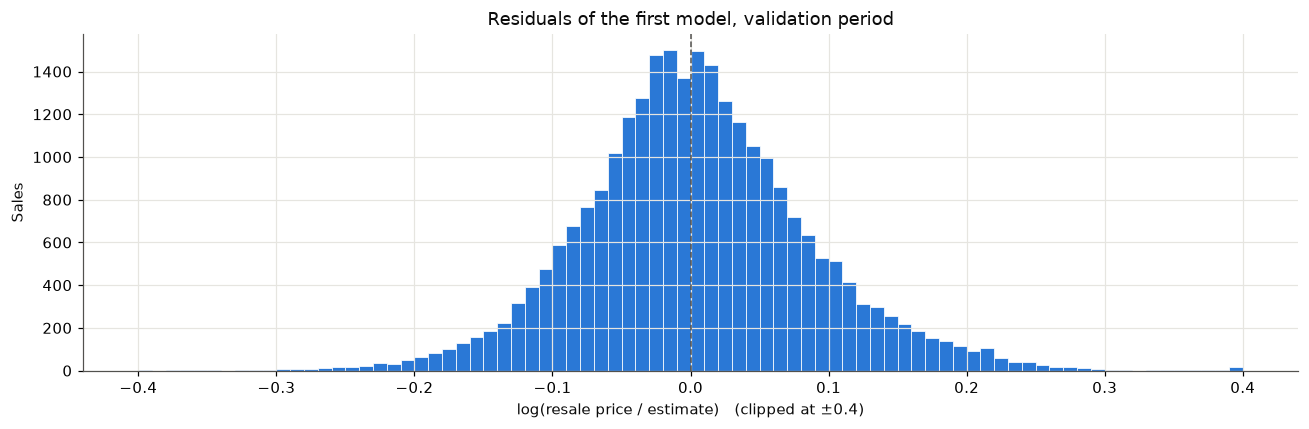

In [2]:
first = residuals(
    backtest(cleaned, HedonicRegression(), train_months=12, end=TEST_START)
)
first_pct_error = (first["estimate"] - first["resale_price"]).abs() / first[
    "resale_price"
]

print(f"{len(first):,} validation sales")
print(f"Bias (mean residual): {first['residual'].mean():+.2%}")
print(f"Spread (standard deviation of the residuals): {first['residual'].std():.3f}")
half, nine_in_ten = first_pct_error.median(), first_pct_error.quantile(0.9)
print(f"% error: half within {half:.1%}, 9 in 10 within {nine_in_ten:.1%}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(
    first["residual"].clip(-0.4, 0.4),
    bins=80,
    color=SERIES[0],
    edgecolor="white",
    linewidth=0.5,
)
ax.axvline(0, color="#52514e", linewidth=1, linestyle="--")
ax.set(
    title="Residuals of the first model, validation period",
    xlabel="log(resale price / estimate)   (clipped at ±0.4)",
    ylabel="Sales",
)
plt.tight_layout()

<a id="toc-1b"></a>

### (b) By driver

Mean residual and spread per group, for the main drivers. One trap to avoid: grouping residuals by the **real price** always shows the cheapest sales underestimated and the dearest overestimated, or the reverse, whether or not the model is biased. A flat that sold unusually high lands in the top price group *because* of its positive error: that's **regression to the mean**. The honest grouping is by the **estimate**, which the model knew before the sale.

In [3]:
def by_group(
    data: pd.DataFrame, group: pd.Series | str, min_sales: int = 50
) -> pd.DataFrame:
    # Mean residual (bias) and spread per group, for groups with enough sales
    table = data.groupby(group, observed=True)["residual"].agg(
        sales="size", bias="mean", spread="std"
    )
    return table[table["sales"] >= min_sales]


# Same residuals, grouped by real price (misleading) and by estimate (honest), in tenths
grouping = pd.DataFrame(
    {
        "by real price": by_group(
            first, pd.qcut(first["resale_price"], 10, labels=range(1, 11))
        )["bias"],
        "by estimate": by_group(
            first, pd.qcut(first["estimate"], 10, labels=range(1, 11))
        )["bias"],
    }
)
grouping.index.name = "tenth (1 = cheapest)"
grouping.style.format("{:+.1%}")

,by real price,by estimate
tenth (1 = cheapest),,
1,-1.5%,+3.6%
2,+1.1%,-0.5%
3,-1.1%,+0.4%
4,-1.4%,-0.4%
5,-2.5%,-0.6%
6,-2.2%,-0.5%
7,-0.3%,-0.8%
8,+1.8%,-1.0%
9,+3.6%,+1.1%


In [4]:
# The largest biases for the other drivers (mean residual, groups of 50+ sales)
lease_band = pd.cut(
    first["remaining_lease_years"],
    [0, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 100],
    right=False,
)
for name, group in [
    ("town", "town"),
    ("flat model group", "flat_model_group"),
    ("storey range", "storey_range"),
    ("lease band", lease_band),
]:
    table = by_group(first, group)
    worst = table["bias"].abs().idxmax()
    print(
        f"{name:>16}: largest bias {table.loc[worst, 'bias']:+.1%} ({worst}, {table.loc[worst, 'sales']:,} sales)"
    )

            town: largest bias +1.7% (MARINE PARADE, 167 sales)
flat model group: largest bias +1.0% (New Generation, 3,001 sales)
    storey range: largest bias -1.6% (31 TO 33, 82 sales)
      lease band: largest bias +1.4% ([45, 50), 960 sales)


In [5]:
# A hypothesis from the EDA: new flats in mature (older, central) estates are worth more
# than the model's town + lease effects add up to. HDB's list of mature estates:
MATURE_ESTATES = {
    "ANG MO KIO",
    "BEDOK",
    "BISHAN",
    "BUKIT MERAH",
    "BUKIT TIMAH",
    "CENTRAL AREA",
    "CLEMENTI",
    "GEYLANG",
    "KALLANG/WHAMPOA",
    "MARINE PARADE",
    "PASIR RIS",
    "QUEENSTOWN",
    "SERANGOON",
    "TAMPINES",
    "TOA PAYOH",
}


def new_in_mature(data: pd.DataFrame) -> pd.DataFrame:
    # Mean residual by estate type and flat age (90+ years of lease left = new)
    groups = [
        np.where(
            data["town"].isin(MATURE_ESTATES), "mature estate", "non-mature estate"
        ),
        np.where(data["remaining_lease_years"] >= 90, "new (90+ years left)", "older"),
    ]
    return (
        data.groupby(groups)["residual"]
        .agg(sales="size", bias="mean")
        .unstack()["bias"]
    )


new_in_mature(first).style.format("{:+.1%}")

,new (90+ years left),older
mature estate,+4.3%,-0.2%
non-mature estate,-1.1%,+0.8%


### Findings (section 1)

- **The first model is almost unbiased overall** (+0.4%, very slightly low), but its spread is wide: half the estimates within 4.9%, 9 in 10 only within 13.5%.
- **Grouping by real price is misleading.** It shows the dearest tenth 6.6% underestimated; grouped by estimate, the same residuals show +2.5%. The honest picture: the cheapest and the dearest tenths are underestimated (+3.6% and +2.5%), everything in between is within ±1%.
- **Each driver is fitted well on average:** no town, flat model group, storey range or lease band is off by more than 1.7%.
- **One interaction candidate:** new flats (90+ years left) in mature estates sell 4.3% above their estimate, while new flats elsewhere sell 1.1% below. The model adds town and lease effects independently, so newness gets the same premium everywhere.
- **Location within the town dominates what's left** (section 1(c)): the town explains none of the residual variance (it's already in the model), but the street accounts for up to half of it and the block for up to three quarters.

<a id="toc-1c"></a>

### (c) Where the remaining error sits

How much of the residual variance is explained by **which town, street or block** a flat is in? For each level, the share of variance captured by the group means (groups with 5+ validation sales). It's an upper bound (group means fitted on the same residuals flatter small groups), so the real test is out of sample, in section 2.

In [6]:
first["block_id"] = first["block"] + " " + first["street_name"]
shares = {}
for level in ["town", "street_name", "block_id"]:
    size = first.groupby(level)["residual"].transform("size")
    enough = first[size >= 5]
    group_mean = enough.groupby(level)["residual"].transform("mean")
    explained = (
        1
        - ((enough["residual"] - group_mean) ** 2).sum()
        / ((enough["residual"] - enough["residual"].mean()) ** 2).sum()
    )
    shares[level] = {
        "groups": first[level].nunique(),
        "share of residual variance": explained,
    }
pd.DataFrame(shares).T.style.format(
    {"groups": "{:,.0f}", "share of residual variance": "{:.0%}"}
)

,groups,share of residual variance
town,26,0%
street_name,559,51%
block_id,"8,079",75%


<a id="toc-2"></a>

## 2. Finer location: street and block

The model gets the location at three levels: the town, plus the **street**, plus the **block** (one building: its number and street). A finer level adds one category: about 560 streets, about 8,000 blocks per 12-month window. A flat whose street or block has no sale in its training window falls back to the next coarser model (block → street → town), so every flat gets an estimate. Each level runs a full validation backtest.

In [7]:
LOCATIONS = ["town", "street", "block"]
location_runs = {
    location: backtest(
        cleaned, HedonicRegression(location=location), train_months=12, end=TEST_START
    )
    for location in LOCATIONS
}
location_scores = {location: score(runs) for location, runs in location_runs.items()}

summary = pd.DataFrame(
    {
        location: scores[["log_mae", "mdape", "p90_ape", "mae", "bias"]].mean()
        for location, scores in location_scores.items()
    }
).T
summary.style.format(
    {
        "log_mae": "{:.4f}",
        "mdape": "{:.2%}",
        "p90_ape": "{:.1%}",
        "mae": "S${:,.0f}",
        "bias": "{:+.2%}",
    }
)

,log_mae,mdape,p90_ape,mae,bias
town,0.0634,4.95%,13.5%,"S$41,747",+0.39%
street,0.0452,3.60%,9.5%,"S$29,059",+0.39%
block,0.0387,3.00%,8.2%,"S$24,981",+0.36%


In [8]:
# Month by month: does each finer level beat the coarser one consistently?
for finer, coarser in [("street", "town"), ("block", "street")]:
    wins = (
        location_scores[finer]["log_mae"] < location_scores[coarser]["log_mae"]
    ).sum()
    print(f"{finer} beats {coarser} in {wins} of the 12 validation months")

street beats town in 12 of the 12 validation months
block beats street in 12 of the 12 validation months


**The block model's training window, re-chosen.** About 8,000 blocks need more sales each than 26 towns do, so the 12-month window chosen for the first model may be too short. Each option runs a full validation backtest, compared on average and month by month, as before.

In [9]:
BLOCK_WINDOWS = [12, 18, 24, 36, 48]
block_windows = {
    months: score(
        backtest(
            cleaned,
            HedonicRegression(location="block"),
            train_months=months,
            end=TEST_START,
        )
    )
    for months in BLOCK_WINDOWS
}
log_mae = pd.DataFrame(
    {months: scores["log_mae"] for months, scores in block_windows.items()}
)
head_to_head = pd.DataFrame(
    {other: (log_mae[row] < log_mae[other]).sum() for other in BLOCK_WINDOWS}
    for row in BLOCK_WINDOWS
)
head_to_head.index = BLOCK_WINDOWS
print(
    "Validation log-space MAE:",
    {months: round(float(log_mae[months].mean()), 4) for months in BLOCK_WINDOWS},
)
print("Months (of 12) the row window beats the column window:")
head_to_head

Validation log-space MAE: {12: 0.0387, 18: 0.038, 24: 0.0377, 36: 0.0379, 48: 0.0389}
Months (of 12) the row window beats the column window:


,12,18,24,36,48
12,0,1,1,2,8
18,11,0,2,4,11
24,11,10,0,8,12
36,10,8,4,0,12
48,4,1,0,0,0


In [10]:
# The chosen window, and the block model's validation run that sections 3 and 4 read
BLOCK_MONTHS = 24
block_run = backtest(
    cleaned,
    HedonicRegression(location="block"),
    train_months=BLOCK_MONTHS,
    end=TEST_START,
)
block_scores = score(block_run)

### Findings (section 2)

- **Each finer level of location is a large, consistent gain:** log-space MAE from 0.063 (town) to 0.045 (street) to 0.039 (block); MdAPE from 5.0% to 3.6% to 3.0%; each level beats the coarser one in all 12 validation months. A block's level captures everything specific to the building: its exact location, its height, views, upkeep.
- **The block model needs a longer window:** 24 months is best (log-space MAE 0.0377), beating 12 months in 11 of 12 validation months, 18 in 10 and 36 in 8. About 8,000 blocks need more sales each than the town model's effects did, which is why the window is longer than the first model's 12 months.
- The block model is kept, with a **24-month** window.

<a id="toc-3"></a>

## 3. Geocoding and a tree model

<a id="toc-3a"></a>

### (a) Geocoding (OneMap)

Geocoding would turn each address into coordinates (and distances to MRT stations, the city centre…) through OneMap, which needs a separate account and terms. With block-level location, the model already knows each building's level; coordinates would mainly help flats on blocks **with no sale** in their training window, which fall back to the street level, by borrowing from neighbouring blocks.

In [11]:
# Flats on blocks with no sale in their training window, and their error
block_id = block_run["block"] + " " + block_run["street_name"]
seen = pd.Series(False, index=block_run.index)
for test_month in block_run["month"].unique():
    window = cleaned[
        (cleaned["month"] < test_month)
        & (cleaned["month"] >= test_month - BLOCK_MONTHS)
    ]
    in_month = block_run["month"] == test_month
    seen[in_month] = block_id[in_month].isin(
        set(window["block"] + " " + window["street_name"])
    )

pct_error = (block_run["estimate"] - block_run["resale_price"]).abs() / block_run[
    "resale_price"
]
print(f"Validation flats on a block with no recent sale: {(~seen).mean():.1%}")
print(
    f"MdAPE: {pct_error[seen].median():.2%} on known blocks, {pct_error[~seen].median():.2%} on new ones"
)

Validation flats on a block with no recent sale: 2.0%
MdAPE: 2.95% on known blocks, 4.44% on new ones


**Findings (3a).** With a 24-month window, only **2.0%** of validation flats are on a block with no recent sale; they're estimated less well (MdAPE 4.4% vs 2.95%). Even if coordinates brought them to the level of known blocks, the overall typical error would improve by about 0.03 points. That doesn't justify OneMap's separate account, terms and legal check: **geocoding is deferred**, to revisit if new blocks become a larger share (e.g. as new estates reach their first resales) or if the price range needs neighbourhood information.

<a id="toc-3b"></a>

### (b) A tree-based model

Trees build thresholds and **interactions** (an effect that depends on another driver) automatically, where a linear model adds independent effects. The lease bands already give the linear model its thresholds, so a tree earns its place only if the residuals show interactions. The candidate from section 1(b), new flats in mature estates, re-checked with block-level location:

In [12]:
pd.DataFrame(
    {
        "town-level model": new_in_mature(first).stack(),
        "block-level model": new_in_mature(residuals(block_run)).stack(),
    }
).style.format("{:+.1%}")

**Findings (3b).** The new-flat premium in mature estates falls from **+4.3% to −0.8%** with block-level location: it wasn't an interaction between lease and town, but location. New flats in mature estates sit on specific redevelopment streets and blocks, whose levels the model now knows. No other group shows a bias large enough to point to an interaction, so **a tree-based model isn't justified by the residuals**; it's left for later, should new residuals show interactions.

<a id="toc-4"></a>

## 4. The primary metric and the "good enough" threshold

The **primary metric** chooses between models and will gate them in CI (step 5), so it must reward what matters to a buyer and be hard to fool. The block model's validation errors:

In [13]:
q50, q75, q90, q95 = (pct_error.quantile(q) for q in [0.5, 0.75, 0.9, 0.95])
print(
    f"Half within {q50:.1%}, 3 in 4 within {q75:.1%}, 9 in 10 within {q90:.1%}, 19 in 20 within {q95:.1%}"
)
print(f"Off by more than 10%: {(pct_error > 0.10).mean():.1%} of flats")

Half within 3.0%, 3 in 4 within 5.2%, 9 in 10 within 7.9%, 19 in 20 within 10.0%
Off by more than 10%: 5.0% of flats


| Metric | For | Against |
|---|---|---|
| MdAPE | very intuitive ("half within 3%") | **blind to the tail**: a model making the worst-estimated tenth much worse would score the same |
| MAPE | counts every error, in % | **asymmetric**: 20% too high costs more than 20% too low (a too-low estimate can't exceed 100% error), so optimising it nudges models to underestimate |
| **log-space MAE** | counts every error; **symmetric** (10% too high ≈ 10% too low); matches the log-price target | a little less intuitive: 0.038 ≈ "3.8% on average" |
| MAE (S\$) | speaks dollars | dominated by expensive flats, while buyers think in % |

**Primary: log-space MAE.** **Headline for humans:** MdAPE and the 90th percentile of the % error; **secondary:** MAE in S\$. One metric to optimise and gate on, readable ones to communicate.

**A good prediction has three aspects**, and a model can be good on one and bad on another: its **bias** (too high or too low on average: errors that cancel out still mean bad verdicts for those buyers), its **typical error**, and its **spread** (how wrong the worst-estimated flats are). The "good enough" threshold covers all three (project ADR-0006), averaged over the backtest windows:

| Condition | Why |
|---|---|
| log-space MAE ≤ **half the reference baseline's** | clearly worth its complexity over what a buyer can already look up |
| log-space MAE ≤ **0.05** | about 5% on average; flats in the same block and year already spread about ±3% (EDA, section 3), close to the floor |
| **9 in 10** estimates within **10%** | so a listing priced 10% above its flats' value can be told apart |
| bias within **±1%** | so verdicts aren't tilted toward "expensive" or "cheap" |

`backtest.good_enough()` checks the four conditions. On validation:

In [14]:
validation_baseline = score(
    backtest(cleaned, TownFlatTypeMedian(recent_months=6), end=TEST_START)
)
good_enough(block_scores, validation_baseline)

half_the_baseline    True
log_mae              True
p90_ape              True
bias                 True
dtype: bool

<a id="toc-5"></a>

## 5. The final model on the test period

The block-level model (24-month window, lease bands), as chosen on validation, runs **once** on the test period, next to the first model and the reference baseline.

In [15]:
final_candidates = {
    "Town + flat type median": (TownFlatTypeMedian(recent_months=6), None),
    "Hedonic regression, town": (HedonicRegression(), 12),
    "Hedonic regression, block": (HedonicRegression(location="block"), BLOCK_MONTHS),
}
test = {
    name: score(backtest(cleaned, model, train_months=months))
    for name, (model, months) in final_candidates.items()
}
pd.DataFrame(
    {
        name: scores[["log_mae", "mdape", "p90_ape", "mae", "bias"]].mean()
        for name, scores in test.items()
    }
).T.style.format(
    {
        "log_mae": "{:.4f}",
        "mdape": "{:.1%}",
        "p90_ape": "{:.1%}",
        "mae": "S${:,.0f}",
        "bias": "{:+.2%}",
    }
)

,log_mae,mdape,p90_ape,mae,bias
Town + flat type median,0.1219,8.6%,25.7%,"S$81,859",+1.03%
"Hedonic regression, town",0.0681,5.3%,14.5%,"S$46,155",-0.04%
"Hedonic regression, block",0.0407,3.1%,8.7%,"S$26,951",-0.11%


half_the_baseline    True
log_mae              True
p90_ape              True
bias                 True 

Block beats town-level in 12 of the 12 test months


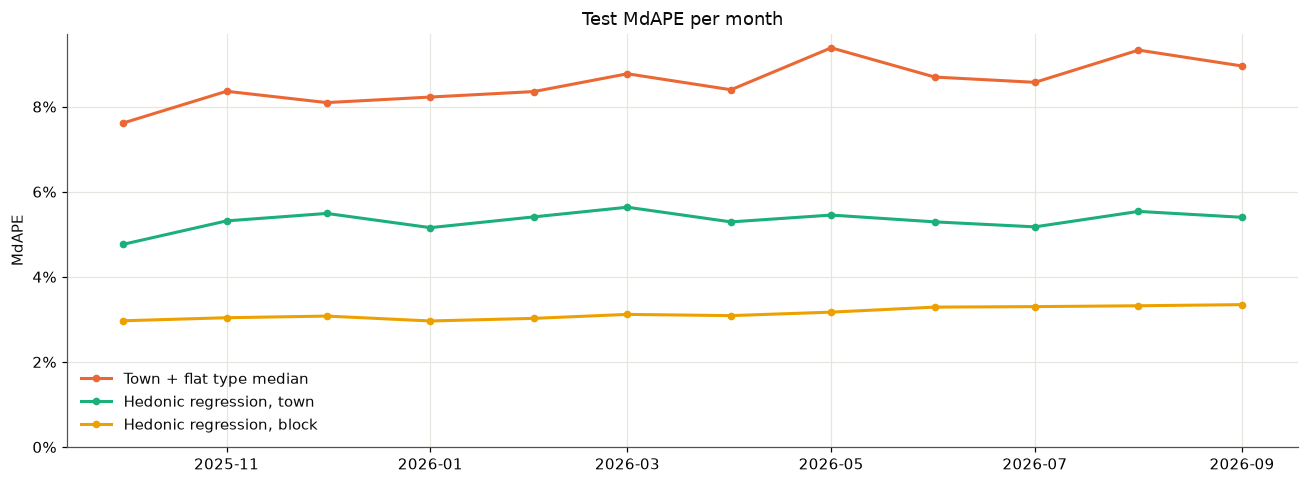

In [16]:
# The threshold on the test period, and the month-by-month comparison
print(
    good_enough(
        test["Hedonic regression, block"], test["Town + flat type median"]
    ).to_string(),
    "\n",
)
wins = (
    test["Hedonic regression, block"]["log_mae"]
    < test["Hedonic regression, town"]["log_mae"]
).sum()
print(f"Block beats town-level in {wins} of the 12 test months")

fig, ax = plt.subplots(figsize=(12, 4.5))
for color, (name, scores) in zip(SERIES[1:], test.items(), strict=True):
    ax.plot(
        scores.index.to_timestamp(),
        scores["mdape"],
        color=color,
        marker="o",
        markersize=4,
        label=name,
    )
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_ylim(bottom=0)
ax.legend(frameon=False, loc="lower left")
ax.set(title="Test MdAPE per month", ylabel="MdAPE")
plt.tight_layout()

### Findings (section 5)

- **The block-level model reaches MdAPE 3.1% on the test period** (log-space MAE 0.041), against 5.3% for the first model and 8.6% for the reference baseline. 9 in 10 estimates are within 8.7%, the average error is S\$27k, and the bias is −0.1%.
- **It meets every condition of the "good enough" threshold** (ADR-0006), and beats the first model in all 12 test months.
- **Test is a little worse than validation** (log-space MAE 0.041 vs 0.038), as for every model so far: the winner's curse and the market's moves. The test score is the honest one.
- *Process note:* an early draft of this notebook also scored a 12-month block model on the test period, before its window was re-chosen. That score played no part in the choice, made on validation only, and isn't reported.

<a id="toc-6"></a>

## 6. Summary: decisions

| Finding | Decision |
|---|---|
| Location within the town dominates the first model's error; street, then block, each win in 12 of 12 validation months | **Block-level location**, falling back to street then town for a block or street with no recent sale |
| The block model is best with a 24-month window | Training window **24 months**, chosen on validation |
| Test MdAPE 3.1% (log-space MAE 0.041), better than the first model in all 12 test months | **The current model**: hedonic regression, block-level, 24 months |
| Only 2% of flats on a block with no recent sale; geocoding would gain about 0.03 points | **OneMap geocoding deferred** |
| The only interaction candidate (new flats in mature estates) was location | **No tree-based model** for now: not justified by the residuals |
| MdAPE is blind to the tail, MAPE is asymmetric, MAE in S\$ is dominated by expensive flats | **Primary metric: log-space MAE**; MdAPE and the 90th percentile as headline, MAE in S\$ as secondary (project ADR-0006) |
| A prediction has a bias, a typical error and a spread | **"Good enough"**: log-space MAE ≤ half the baseline's and ≤ 0.05, 9 in 10 within 10%, bias within ±1% (ADR-0006, `good_enough()`); the block model meets all four |
| The cheapest and dearest tenths are underestimated (+2–4% for the first model) | Noted for the price range: its width may need to vary with the estimate |